# LAB 03 — Naive Bayes: từ bằng chứng đến xác suất

**DNU Learning Analytics Lab**

- **Họ tên:** Lê Trung Kiên
- **MSSV:** 1771020404
- **Lớp:** CNTT 18-02

> **Câu hỏi trung tâm:** Nếu K-NN dự đoán bằng những sinh viên ‘gần’ nhất, Naive Bayes sẽ dự đoán cùng một sinh viên như thế nào bằng xác suất?

Lab 03 dùng **cùng bài toán, cùng feature, cùng target và cùng train/test split của Lab 02** để việc so sánh có ý nghĩa.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from nb_manual import compute_class_priors, gaussian_log_likelihood
DATA_PATH = Path('data/StudentPerformanceFactors.csv')
print('Environment ready! Dataset exists:', DATA_PATH.exists())

Environment ready! Dataset exists: True


# Mission 1 — Back to DNU case study

Tạo nhãn giảng dạy `Needs_Support = 1` nếu `Exam_Score < 65`, ngược lại là 0. Giữ đúng bài toán của Lab 02.

**Quan trọng:** không dùng `Exam_Score` làm feature vì sẽ gây target leakage.

[TRẢ LỜI]
1. **Vì sao đây là Target Leakage?**
   - Nhãn target `Needs_Support` được tạo ra trực tiếp từ logic toán học `Exam_Score < 65`. 
   - Nếu đưa `Exam_Score` vào danh sách features đầu vào, mô hình sẽ "thấy trước đáp án" (chỉ cần lấy `Exam_Score` so sánh với 65 là biết ngay kết quả). 
   - Điều này dẫn đến hiệu năng ảo (Accuracy = 100%) trên tập dữ liệu hiện tại, nhưng mô hình sẽ hoàn toàn vô dụng trên thực tế khi cần dự đoán sớm cho học sinh trước khi kỳ thi diễn ra.

2. **Vì sao cần dùng cùng train/test split (cùng random_state/test_size) như Lab 02?**
   - **Đảm bảo tính so sánh công bằng (Fair Comparison):** Khi giữ nguyên tập train và tập test chính xác tới từng dòng dữ liệu như ở Lab 02, mọi sự thay đổi/cải thiện về kết quả (như Accuracy, Precision, Recall, F1) giữa các mô hình (ví dụ: Naive Bayes/Decision Tree của Lab 03 so với KNN của Lab 02) mới thực sự đến từ sự khác biệt của **thuật toán** chứ không phải do sự may mắn/khác biệt của **mẫu dữ liệu**.
   - **Tránh lệch phân bố dữ liệu:** Giúp kiểm soát nhất quán các yếu tố thực nghiệm qua các bài lab khác nhau trên cùng một case study DNU.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError('Run: python scripts/download_data.py')
df = pd.read_csv(DATA_PATH).copy()
df['Needs_Support'] = (df['Exam_Score'] < 65).astype(int)
feature_cols = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours']
assert 'Exam_Score' not in feature_cols
model_df = df[feature_cols + ['Needs_Support']].dropna().copy()
X = model_df[feature_cols]
y = model_df['Needs_Support']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
display(y_train.value_counts(normalize=True).rename('prior').to_frame())

Train: (4955, 4) Test: (1652, 4)


,prior
Needs_Support,
0,0.780222
1,0.219778


# Mission 2 — Prior first

Hoàn thiện `compute_class_priors(y)` trong `nb_manual.py`.

**[TRẢ LỜI]** `P(Needs_Support=1)` có ý nghĩa gì? Prior có phụ thuộc vào feature của sinh viên mới không?

In [3]:
try:
    priors_manual = compute_class_priors(y_train.to_numpy())
    print('Manual priors:', priors_manual)
    print('Pandas check:', y_train.value_counts(normalize=True).sort_index().to_dict())
except NotImplementedError as e:
    print('TODO in nb_manual.py ->', e)

Manual priors: {np.int64(0): np.float64(0.7802219979818366), np.int64(1): np.float64(0.21977800201816347)}
Pandas check: {0: 0.7802219979818366, 1: 0.21977800201816347}


# Mission 3 — Gaussian evidence: model học gì?

Hoàn thiện `gaussian_log_likelihood(x, mean, var)` trong `nb_manual.py`, sau đó huấn luyện `GaussianNB`.

Quan sát `class_prior_`, `theta_`, `var_`.

**[TRẢ LỜI]** `theta_` và `var_` biểu diễn gì? GaussianNB có lưu toàn bộ hàng xóm như K-NN không?

1. **`theta_` và `var_` biểu diễn gì?**
   - **`theta_` (`gnb.theta_`):** Biểu diễn giá trị trung bình (Mean - $\mu$) của từng đặc trưng (feature) cho từng lớp (class).
   - **`var_` (`gnb.var_`):** Biểu diễn phương sai (Variance - $\sigma^2$) của từng đặc trưng cho từng lớp.
   - Đây chính là các tham số của phân phối chuẩn (Gaussian distribution) mà mô hình đã "học" được từ dữ liệu huấn luyện.

2. **GaussianNB có lưu toàn bộ hàng xóm như K-NN không?**
   - **Không.**
   - **K-NN** là mô hình **Non-parametric / Lazy Learning**: phải lưu trữ toàn bộ dữ liệu huấn luyện để tính khoảng cách mỗi khi dự đoán.
   - **GaussianNB** là mô hình **Parametric Model**: sau khi huấn luyện, nó chỉ lưu lại các tham số tóm tắt thống kê ($\mu$ trong `theta_`, $\sigma^2$ trong `var_`, và xác suất tiền định `class_prior_`). Khi dự đoán dữ liệu mới, mô hình dùng trực tiếp các tham số này để tính toán chứ không cần giữ lại dữ liệu gốc.

In [4]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
print('Classes:', gnb.classes_)
print('Class priors:', gnb.class_prior_)
theta_df = pd.DataFrame(gnb.theta_, index=[f'class_{c}' for c in gnb.classes_], columns=feature_cols)
var_df = pd.DataFrame(gnb.var_, index=[f'class_{c}' for c in gnb.classes_], columns=feature_cols)
display(theta_df)
display(var_df)
sample0 = X_test.iloc[0]
attendance_idx = feature_cols.index('Attendance')
x_value = float(sample0['Attendance'])
for row_idx, class_label in enumerate(gnb.classes_):
    try:
        ll = gaussian_log_likelihood(x_value, float(gnb.theta_[row_idx, attendance_idx]), float(gnb.var_[row_idx, attendance_idx]))
        print(f'class={class_label}, Attendance log-likelihood={ll:.4f}')
    except NotImplementedError as e:
        print('TODO in nb_manual.py ->', e)
        break

Classes: [0 1]
Class priors: [0.780222 0.219778]


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
class_0,21.129850,82.929384,76.102431,7.035954
class_1,15.768595,69.261708,71.642792,7.051423


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
class_0,32.846047,113.289633,204.633585,2.193482
class_1,25.854625,56.782749,197.215837,2.162645


class=0, Attendance log-likelihood=-3.5614
class=1, Attendance log-likelihood=-3.2285


# Mission 4 — Evaluate beyond Accuracy

Đánh giá Accuracy, Precision, Recall, F1 và Confusion Matrix.

Đặc biệt chú ý **False Negative**: sinh viên thực tế cần hỗ trợ (`1`) nhưng model dự đoán không cần hỗ trợ (`0`).

**[TRẢ LỜI]** Vì sao chỉ nhìn Accuracy là chưa đủ?

**Vì sao chỉ nhìn Accuracy là chưa đủ?**

1. **Hiện tượng mất cân bằng lớp (Class Imbalance):**
   - Trong tập dữ liệu, số lượng sinh viên không cần hỗ trợ (`No Support` = 1289) chiếm tỷ lệ áp đảo (~78%) so với sinh viên cần hỗ trợ (`Needs Support` = 363)[cite: 11].
   - Chỉ số Accuracy cao (~87.8%) chủ yếu phản ảnh việc mô hình dự đoán đúng lớp đa số (`No Support`), dễ tạo ra cảm giác ảo tưởng rằng mô hình hoạt động rất tốt[cite: 11].

2. **Che giấu lỗi False Negative (FN) nguy hại:**
   - Trong ứng dụng giáo dục thực tế, việc bỏ sót sinh viên gặp khó khăn (**False Negative = 147**) gây hậu quả nghiêm trọng hơn rất nhiều so with việc dự đoán nhầm sinh viên học tốt thành cần hỗ trợ[cite: 11].
   - Dù Accuracy đạt gần 88%, chỉ số **Recall của lớp `Needs Support` chỉ đạt ~59.5%**[cite: 11]. Điều này cho thấy mô hình đang bỏ sót hơn **40%** sinh viên thực sự cần nhà trường giúp đỡ. 
   - Do đó, ta cần xem xét thêm các chỉ số như **Recall**, **Precision**, và **F1-score** để có cái nhìn toàn diện và chính xác hơn về hiệu năng thực sự của mô hình.

,model,accuracy,precision,recall,f1,tn,fp,fn,tp
0,GaussianNB,0.878329,0.8,0.595041,0.682464,1235,54,147,216


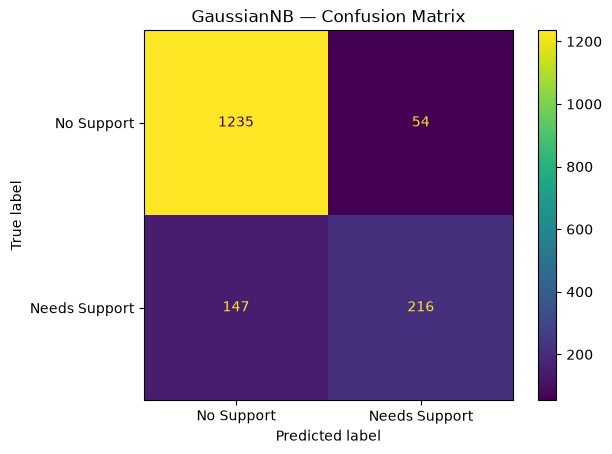

               precision    recall  f1-score   support

   No Support       0.89      0.96      0.92      1289
Needs Support       0.80      0.60      0.68       363

     accuracy                           0.88      1652
    macro avg       0.85      0.78      0.80      1652
 weighted avg       0.87      0.88      0.87      1652



In [5]:
def evaluate_binary(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {'model': name, 'accuracy': accuracy_score(y_true,y_pred), 'precision': precision_score(y_true,y_pred,zero_division=0), 'recall': recall_score(y_true,y_pred,zero_division=0), 'f1': f1_score(y_true,y_pred,zero_division=0), 'tn':tn, 'fp':fp, 'fn':fn, 'tp':tp}
nb_pred = gnb.predict(X_test)
nb_result = evaluate_binary('GaussianNB', y_test, nb_pred)
display(pd.DataFrame([nb_result]))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=['No Support','Needs Support'])
plt.title('GaussianNB — Confusion Matrix')
plt.show()
print(classification_report(y_test, nb_pred, target_names=['No Support','Needs Support'], zero_division=0))

# Mission 5 — Explain one student

Chọn một sample trong `X_test`, xem `predict_proba()` và thử tính log-score từ log prior + Gaussian log-likelihood của từng feature.

> Đây không phải feature importance; ta đang xem likelihood cho một dự đoán cụ thể.

**[TRẢ LỜI]** Model dự đoán lớp nào? Bằng chứng nào có vẻ nghiêng nhiều hơn về lớp đó?
1. **Model dự đoán lớp nào?**
   - Mô hình dự đoán sinh viên thuộc **lớp 0 (`No Support` - Không cần hỗ trợ)** với xác suất $P(\text{class}=0 \mid X) \approx 92.12\%$ (`total_log_score` = -12.274042).

2. **Bằng chứng nào có vẻ nghiêng nhiều hơn về lớp đó?**
   - **Xác suất tiền định (`log_prior`):** Bằng chứng tiền định ưu thế hơn hẳn cho lớp 0 (-0.248177) do lớp 0 chiếm đa số trong dữ liệu.
   - **Số giờ học (`ll_Hours_Studied`):** Sinh viên học 24 giờ/tuần, mức này ủng hộ mạnh mẽ lớp 0 hơn (-2.790254 so với -3.855510 của lớp 1).
   - **Điểm số các kỳ trước (`ll_Previous_Scores`):** Sinh viên đạt điểm thi cũ rất cao (94 điểm), đóng góp log-likelihood nghiêng rõ rệt về lớp 0 (-4.362223 so với -4.828341).

=> **Kết luận:** Tổng hợp `log_prior` cùng các bằng chứng từ số giờ học và điểm số cũ đã áp đảo hoàn toàn, giúp mô hình tự tin phân loại sinh viên này vào lớp không cần hỗ trợ.

In [6]:
student_x = X_test.iloc[[0]]
display(student_x)
pred_class = int(gnb.predict(student_x)[0])
proba = gnb.predict_proba(student_x)[0]
for cls, p in zip(gnb.classes_, proba):
    print(f'P(class={cls} | X) = {p:.6f}')
try:
    x_arr = student_x.iloc[0].to_numpy(dtype=float)
    rows = []
    for i, cls in enumerate(gnb.classes_):
        log_prior = math.log(float(gnb.class_prior_[i]))
        feature_ll = [gaussian_log_likelihood(float(x_arr[j]), float(gnb.theta_[i,j]), float(gnb.var_[i,j])) for j in range(len(feature_cols))]
        rows.append({'class': int(cls), 'log_prior': log_prior, **{f'll_{f}':v for f,v in zip(feature_cols,feature_ll)}, 'total_log_score': log_prior + sum(feature_ll)})
    score_df = pd.DataFrame(rows)
    display(score_df)
    print('Manual argmax:', int(score_df.loc[score_df.total_log_score.idxmax(),'class']), 'sklearn:', pred_class)
except NotImplementedError as e:
    print('TODO in nb_manual.py ->', e)

,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
3214,24,75,94,7


P(class=0 | X) = 0.921193
P(class=1 | X) = 0.078807


,class,log_prior,ll_Hours_Studied,ll_Attendance,ll_Previous_Scores,ll_Sleep_Hours,total_log_score
0,0,-0.248177,-2.790254,-3.561410,-4.362223,-1.311978,-12.274042
1,1,-1.515137,-3.855510,-3.228502,-4.828341,-1.305216,-14.732707


Manual argmax: 0 sklearn: 0


# Mission 6 — K-NN vs Naive Bayes

So sánh hai cách suy luận trên **cùng test set**. K-NN tham chiếu dùng `K=5`, Euclidean và `StandardScaler`.

**[TRẢ LỜI]** Tìm ít nhất 3 sample hai model dự đoán khác nhau và giải thích vì sao chúng có thể bất đồng.
### 1. 3 sample có sự bất đồng giữa 2 mô hình:

* **Mẫu index 24:** 
  * `Hours_Studied` = 13, `Attendance` = 71, `Previous_Scores` = 98, `Sleep_Hours` = 7.
  * **Actual** = 1 | **NB_Pred** = 1 | **KNN_Pred** = 0.
* **Mẫu index 33:** 
  * `Hours_Studied` = 22, `Attendance` = 76, `Previous_Scores` = 66, `Sleep_Hours` = 7.
  * **Actual** = 0 | **NB_Pred** = 0 | **KNN_Pred** = 1.
* **Mẫu index 76:** 
  * `Hours_Studied` = 21, `Attendance` = 62, `Previous_Scores` = 94, `Sleep_Hours` = 7.
  * **Actual** = 1 | **NB_Pred** = 0 | **KNN_Pred** = 1.

---

### 2. Vì sao hai mô hình bất đồng:

1. **Khác biệt về bản chất thuật toán (Parametric vs Non-parametric):**
   - **Gaussian Naive Bayes (Parametric):** Giả định các đặc trưng tuân theo phân phối chuẩn (Gaussian) và tính xác suất tổng thể trên toàn bộ tập dữ liệu. Ngoài ra, Naive Bayes giả định tính độc lập giữa các đặc trưng (conditional independence). Do đó, khi một mẫu có điểm số cũ rất cao (như `Previous_Scores` = 98 ở mẫu 24), xác suất xác định bởi phân phối Gaussian có thể bị áp đảo bởi đặc trưng này.
   - **K-NN (Non-parametric):** Dự đoán dựa trên khoảng cách hình học cục bộ (Local Decision Boundary) tới 5 hàng xóm gần nhất. K-NN không giả định phân phối dữ liệu hay tính độc lập giữa các đặc trưng.

2. **Cơ chế hoạt động khi gặp điểm dữ liệu nhiễu hoặc ở ranh giới (Decision Boundary):**
   - Ở **mẫu 24** (`Hours_Studied` thấp = 13, nhưng `Previous_Scores` rất cao = 98): KNN nhìn vào 5 hàng xóm gần nhất trong không gian đã scaling và thấy đa số hàng xóm xung quanh thuộc lớp 0 (do các chỉ số khác khá tốt). Trong khi đó, Naive Bayes tính xác suất tích lũy và đánh giá mức `Hours_Studied` = 13 là bằng chứng mạnh nghiêng về lớp 1 (`Needs Support`), giúp Naive Bayes đoán đúng nhãn thực tế.
   - Ở **mẫu 76** (`Attendance` thấp = 62, `Hours_Studied` trung bình = 21, `Previous_Scores` cao = 94): Naive Bayes bị đánh lừa bởi `Previous_Scores` cao nên dự đoán lớp 0. Tuy nhiên, KNN phát hiện ra trong không gian đa chiều, mẫu này nằm gần vùng mật độ các sinh viên thực tế bị trượt/cần hỗ trợ (lớp 1), nên KNN dự đoán đúng nhãn thực tế.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
knn_result = evaluate_binary('KNN k=5 scaled', y_test, knn_pred)
display(pd.DataFrame([nb_result, knn_result])[['model','accuracy','precision','recall','f1','fn','fp']])
comparison = X_test.reset_index(drop=True).copy()
comparison['Actual'] = y_test.reset_index(drop=True)
comparison['NB_Pred'] = nb_pred
comparison['KNN_Pred'] = knn_pred
comparison['Same'] = comparison['NB_Pred'] == comparison['KNN_Pred']
disagreements = comparison[~comparison['Same']].copy()
print('Number of disagreements:', len(disagreements))
display(disagreements.head(10))

,model,accuracy,precision,recall,f1,fn,fp
0,GaussianNB,0.878329,0.800000,0.595041,0.682464,147,54
1,KNN k=5 scaled,0.860775,0.698507,0.644628,0.670487,129,101


Number of disagreements: 135


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Actual,NB_Pred,KNN_Pred,Same
24,13,71,98,7,1,1,0,False
26,12,77,64,7,1,1,0,False
33,22,76,66,7,0,0,1,False
35,22,64,68,8,0,0,1,False
36,21,62,86,6,0,0,1,False
37,27,62,75,5,0,0,1,False
47,18,61,96,6,1,1,0,False
71,18,68,82,6,0,1,0,False
73,16,67,98,8,1,1,0,False
76,21,62,94,7,1,0,1,False


# Transfer Challenge — Naive Bayes không chỉ dành cho Student Performance

Pipeline: `Text → CountVectorizer → word counts → MultinomialNB → Topic`.

**[TRẢ LỜI]** Vì sao văn bản đếm từ dùng MultinomialNB thay vì GaussianNB?

1. **Bản chất của dữ liệu (Discrete Count Data vs Continuous Data):**
   - **`CountVectorizer`** tạo ra các đặc trưng là **tần số xuất hiện của từ (word counts)** — đây là dữ liệu rời rạc, không âm ($0, 1, 2, 3,...$).
   - **`MultinomialNB`** được thiết kế chuyên biệt cho phân phối đa thức (Multinomial Distribution), cực kỳ phù hợp để mô hình hóa tần suất xuất hiện của các phần tử rời rạc (như số lần từ xuất hiện trong văn bản).

2. **Giả định không phù hợp của GaussianNB:**
   - **`GaussianNB`** giả định dữ liệu đầu vào tuân theo **phân phối chuẩn liên tục (Gaussian distribution)** dạng hình chuông với các giá trị thực từ $-\infty$ đến $+\infty$.
   - Ma trận đếm từ trong xử lý ngôn ngữ tự nhiên (NLP) có tính chất **thưa (sparse matrix)** với rất nhiều số 0 (do một văn bản chỉ chứa một phần rất nhỏ trong tổng số 10,000 từ vựng). Việc ép phân phối chuẩn lên dữ liệu đếm từ nhiều số 0 này sẽ vi phạm nghiêm trọng giả định toán học, dẫn đến hiệu năng dự đoán rất kém.

Mặc định `RUN_TRANSFER=False` để GitHub Actions không phụ thuộc vào tải 20 Newsgroups.

In [9]:
RUN_TRANSFER = True
if RUN_TRANSFER:
    from sklearn.datasets import fetch_20newsgroups
    categories = ['comp.graphics','rec.sport.baseball','sci.space','talk.politics.misc']
    train_text = fetch_20newsgroups(subset='train', categories=categories, remove=('headers','footers','quotes'))
    test_text = fetch_20newsgroups(subset='test', categories=categories, remove=('headers','footers','quotes'))
    vectorizer = CountVectorizer(stop_words='english', max_features=10000)
    X_text_train = vectorizer.fit_transform(train_text.data)
    X_text_test = vectorizer.transform(test_text.data)
    mnb = MultinomialNB(alpha=1.0)
    mnb.fit(X_text_train, train_text.target)
    text_pred = mnb.predict(X_text_test)
    print('20 Newsgroups accuracy:', accuracy_score(test_text.target, text_pred))
else:
    print('Transfer Challenge skipped. Set RUN_TRANSFER=True to run it.')

20 Newsgroups accuracy: 0.8704697986577181


# Final — Model Reflection Card

### 1. Prior, likelihood và posterior khác nhau thế nào?
* **Prior $P(y)$:** Xác suất tiền định của một lớp khi chưa biết bất kỳ thông tin đặc trưng nào (tỷ lệ lớp trong tập train).
* **Likelihood $P(x\vert{}y)$:** Khả năng quan sát được giá trị đặc trưng $x$ khi biết mẫu đó thuộc về lớp $y$.
* **Posterior $P(y\vert{}x)$:** Xác suất hậu định — cơ sở để ra quyết định dự đoán lớp $y$ sau khi đã kết hợp cả niềm tin ban đầu (Prior) và bằng chứng quan sát được (Likelihood) theo công thức Bayes: $P(y\vert{}x) \propto P(y) \cdot P(x\vert{}y)$.

### 2. GaussianNB thực sự học gì từ tập train?
GaussianNB học các tham số thống kê tóm tắt phân phối dữ liệu cho từng lớp:
* **Trung bình ($\mu$ - `theta_`):** Giá trị trung tâm của từng đặc trưng ứng với mỗi lớp.
* **Phương sai ($\sigma^2$ - `var_`):** Độ phân tán/biến động của từng đặc trưng ứng với mỗi lớp.
* **Prior (`class_prior_`):** Tỷ lệ phân bố các lớp trong tập huấn luyện.

### 3. Trong case study `Needs_Support`, lỗi nào đáng chú ý hơn?
Lỗi **False Negative (FN)** đáng chú ý hơn. Nếu dự đoán sai một sinh viên thực sự cần hỗ trợ (`Needs_Support = 1`) thành không cần hỗ trợ (`0`), nhà trường sẽ bỏ sót sinh viên đó và họ không nhận được trợ giúp kịp thời trước kỳ thi.

### 4. Vì sao `Exam_Score` không được dùng làm feature?
Vì nhãn `Needs_Support` được tạo ra trực tiếp từ điều kiện `Exam_Score < 65`. Đưa `Exam_Score` vào làm feature đầu vào sẽ gây ra hiện tượng **Target Leakage** ("thấy trước đáp án"), khiến mô hình đạt độ chính xác ảo 100% nhưng hoàn toàn vô dụng khi triển khai dự đoán trước kỳ thi.

### 5. K-NN và GaussianNB khác nhau ở cách ra quyết định như thế nào?
* **K-NN (Non-parametric / Instance-based):** Ra quyết định dựa trên không gian khoảng cách cục bộ (Euclidean) tới $K$ điểm hàng xóm gần nhất mà không giả định phân phối dữ liệu.
* **GaussianNB (Parametric / Probabilistic):** Ra quyết định dựa trên xác suất toàn cục bằng cách giả định các đặc trưng tuân theo phân phối chuẩn Gaussian và độc lập điều kiện với nhau (Naive Assumption).

### 6. Vì sao 20 Newsgroups dùng MultinomialNB thay vì GaussianNB?
Dữ liệu văn bản từ `CountVectorizer` là dữ liệu rời rạc dạng số lần xuất hiện của từ (word counts) chứa rất nhiều số 0 (thưa thớt). **MultinomialNB** được thiết kế riêng cho phân phối đa thức của dữ liệu đếm rời rạc này, trong khi **GaussianNB** giả định dữ liệu liên tục tuân theo phân phối chuẩn hình chuông nên vi phạm nghiêm trọng giả định toán học.

### 7. Một câu chốt
| Dataset không đổi nhưng dự đoán có thể thay đổi vì...

Dataset không đổi nhưng dự đoán có thể thay đổi vì mỗi thuật toán học máy (KNN, Naive Bayes,...) dựa trên những giả định toán học khác nhau về cấu trúc dữ liệu, từ việc tính khoảng cách hình học cục bộ cho đến việc ước lượng xác suất phân phối toàn cục.